# Perbandingan Deep Learning — CNN 1D Reguler

Notebook ini melatih **CNN 1D reguler** sebagai pembanding deep learning untuk model utama Tabular Conformer.

Protokol diselaraskan dengan notebook `SHAP_XAI_conformer_v2.ipynb`:
- Dataset: `merge_DocLab_balanced.csv`.
- Fitur dan urutan fitur: sama dengan Conformer (13 fitur).
- Target: `NM_UNIT` (kelas 0–3).
- Split stratified: 70% train, 15% validation, 15% test dengan `random_state=42`.
- `StandardScaler` di-fit pada train saja.
- Early stopping berdasarkan macro-F1 validation dan test set hanya digunakan untuk evaluasi akhir.

**Catatan arsitektur:** CNN 1D memperlakukan urutan 13 fitur sebagai dimensi sekuens dan mempelajari pola lokal antarf fitur berdekatan. Karena fitur medis tabular tidak selalu memiliki hubungan urutan alami, CNN ini diposisikan sebagai baseline pembanding, bukan asumsi bahwa urutan fitur memiliki makna temporal.

Dataset ini adalah Plan B hasil balancing. Notebook ini menyamakan evaluasi model, tetapi tidak menghapus keterbatasan dari proses balancing yang dilakukan sebelum splitting pada tahap sebelumnya.

## 1. Import Library dan Setup

In [1]:
import os
import random
import copy
import warnings
warnings.filterwarnings('ignore')

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    balanced_accuracy_score,
    classification_report,
    confusion_matrix,
    ConfusionMatrixDisplay,
)
from imblearn.under_sampling import RandomUnderSampler
from imblearn.over_sampling import SMOTE

import torch
import torch.nn as nn
import torch.nn.functional as F
from torch.utils.data import TensorDataset, DataLoader

SEED = 42
random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)
if torch.cuda.is_available():
    torch.cuda.manual_seed_all(SEED)

torch.backends.cudnn.deterministic = True
torch.backends.cudnn.benchmark = False

device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
print('PyTorch:', torch.__version__)
print('Device :', device)

FEATURES = [
    'JENIS_KELAMIN',
    'UMUR_TAHUN',
    'cholesterol total',
    'creatinin',
    'fbs',
    'rbs',
    'hgb',
    'lymfosit%',
    'mch',
    'mchc',
    'mcv',
    'ureum',
    'wbc',
]

CLASS_NAMES = [
    'Sehat / Tidak Ada Indikasi',
    'Jantung dan Pembuluh Darah',
    'Spes. Penyakit Dalam',
    'Spes. Paru-Paru',
]


PyTorch: 2.14.0+cpu
Device : cpu


## 2. Load Dataset

In [2]:
# OPSI VALIDASI AKADEMIK (OPSI B):
DATA_PATH = 'merge_DocLab_imputed.csv'
# DATA_PATH = 'merge_DocLab_balanced.csv' # Opsi A

df = pd.read_csv(DATA_PATH)

# Perbaiki profil umur dan gender kelas 0 jika masih 0 / 2
mask_0 = df['NM_UNIT'] == 0
if (df.loc[mask_0, 'UMUR_TAHUN'] == 0).all():
    valid_ages = df.loc[df['UMUR_TAHUN'] > 0, 'UMUR_TAHUN']
    mu_age, sd_age = valid_ages.mean(), valid_ages.std()
    df.loc[mask_0, 'UMUR_TAHUN'] = np.clip(
        np.random.normal(mu_age, sd_age, mask_0.sum()), 18, 85
    ).round(0)
    df.loc[mask_0, 'JENIS_KELAMIN'] = np.random.choice([0, 1], size=mask_0.sum(), p=[0.5, 0.5])
    print('Profil demografi kelas kontrol berhasil disesuaikan.')

print('Shape dataset:', df.shape)
df.head()


FileNotFoundError: [Errno 2] No such file or directory: 'merge_DocLab_imputed.csv'

## 3. Validasi Fitur dan Target

In [ ]:
required_cols = FEATURES + ['NM_UNIT']
missing_cols = [col for col in required_cols if col not in df.columns]
if missing_cols:
    raise KeyError(
        f'Kolom tidak ditemukan: {missing_cols}. Samakan nama/urutan fitur dengan notebook Conformer.'
    )

df_model = df[required_cols].copy()
df_model['NM_UNIT'] = pd.to_numeric(df_model['NM_UNIT'], errors='raise').astype(int)
df_model[FEATURES] = df_model[FEATURES].apply(pd.to_numeric, errors='coerce')

missing_features = df_model[FEATURES].isna().sum()
if missing_features.any():
    print('Missing/non-numeric pada fitur:')
    missing_features[missing_features > 0]
    raise ValueError('Dataset masih memiliki missing/non-numeric. Gunakan hasil preprocessing yang sama dengan Conformer.')

classes_found = sorted(df_model['NM_UNIT'].unique().tolist())
print('Kelas:', classes_found)
if classes_found != [0, 1, 2, 3]:
    raise ValueError(f'Target harus [0, 1, 2, 3], ditemukan {classes_found}.')

df_model['NM_UNIT'].value_counts().sort_index().rename(index=dict(enumerate(CLASS_NAMES))).to_frame('Jumlah')

Kelas: [0, 1, 2, 3]


,Jumlah
NM_UNIT,
Sehat / Tidak Ada Indikasi,2812
Jantung dan Pembuluh Darah,52
Spes. Penyakit Dalam,561
Spes. Paru-Paru,20


## 4. Split Data — Sama dengan Conformer

In [ ]:
X = df_model[FEATURES].copy()
y = df_model['NM_UNIT'].to_numpy(dtype=np.int64)

# Gunakan urutan split yang sama persis dengan notebook Tabular Conformer.
X_train, X_temp, y_train, y_temp = train_test_split(
    X,
    y,
    test_size=0.30,
    stratify=y,
    random_state=SEED,
)

X_val, X_test, y_val, y_test = train_test_split(
    X_temp,
    y_temp,
    test_size=0.50,
    stratify=y_temp,
    random_state=SEED,
)

print('Train      :', X_train.shape, y_train.shape)
print('Validation :', X_val.shape, y_val.shape)
print('Test       :', X_test.shape, y_test.shape)

Train      : (2411, 13) (2411,)
Validation : (517, 13) (517,)
Test       : (517, 13) (517,)


## 4.1 Resampling Khusus Training Set (Mencegah Data Leakage)
Resampling (Undersampling & SMOTE) hanya diterapkan pada **`X_train`**.
`X_val` dan `X_test` **dibiarkan 100% data asli** tanpa augmentasi.

In [ ]:
# 1. Undersample kelas mayoritas pada training set
rus = RandomUnderSampler(sampling_strategy={0: 700, 2: 350}, random_state=SEED)
X_train_u, y_train_u = rus.fit_resample(X_train, y_train)

# 2. Domain Augmentation khusus kelas 3 (Paru) pada data train
X_paru_train = X_train_u[y_train_u == 3].copy()
augmented_paru = [X_paru_train]
lab_cols = [c for c in X.columns if c not in ['JENIS_KELAMIN', 'UMUR_TAHUN']]

for _ in range(5):
    synth = X_paru_train.copy()
    jitter = np.random.normal(0, 0.04, size=synth[lab_cols].shape)
    synth[lab_cols] = synth[lab_cols] * (1 + jitter)
    synth['UMUR_TAHUN'] = np.clip(synth['UMUR_TAHUN'] + np.random.randint(-3, 4, size=len(synth)), 18, 85)
    augmented_paru.append(synth)

X_paru_aug = pd.concat(augmented_paru, ignore_index=True)
y_paru_aug = pd.Series([3] * len(X_paru_aug))

X_train_pre = pd.concat([X_train_u[y_train_u != 3], X_paru_aug], ignore_index=True)
y_train_pre = pd.concat([pd.Series(y_train_u[y_train_u != 3]), y_paru_aug], ignore_index=True)

# 3. SMOTE pada training set (kelas 1 dan kelas 3 dinaikkan ke 350 sampel)
smote = SMOTE(sampling_strategy={1: 350, 3: 350}, k_neighbors=3, random_state=SEED)
X_train_res, y_train_res = smote.fit_resample(X_train_pre, y_train_pre)

print("Distribusi y_train ASLI:\n", pd.Series(y_train).value_counts().sort_index())
print("\nDistribusi y_train SETELAH RESAMPLING:\n", pd.Series(y_train_res).value_counts().sort_index())
print("\nDistribusi y_val (TETAP 100% ASLI):\n", pd.Series(y_val).value_counts().sort_index())
print("\nDistribusi y_test (TETAP 100% ASLI):\n", pd.Series(y_test).value_counts().sort_index())

Distribusi y_train ASLI:
 0    1968
1      36
2     393
3      14
Name: count, dtype: int64

Distribusi y_train SETELAH RESAMPLING:
 0    700
1    350
2    350
3    350
Name: count, dtype: int64

Distribusi y_val (TETAP 100% ASLI):
 0    422
1      8
2     84
3      3
Name: count, dtype: int64

Distribusi y_test (TETAP 100% ASLI):
 0    422
1      8
2     84
3      3
Name: count, dtype: int64


## 5. Scaling dan DataLoader

In [ ]:
# Scaling di-fit HANYA pada X_train_res; validation dan test hanya di-transform.
scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train_res).astype(np.float32)
X_val_scaled = scaler.transform(X_val).astype(np.float32)
X_test_scaled = scaler.transform(X_test).astype(np.float32)

BATCH_SIZE = 64

train_dataset = TensorDataset(
    torch.from_numpy(X_train_scaled),
    torch.from_numpy(np.asarray(y_train_res, dtype=np.int64)),
)
val_dataset = TensorDataset(
    torch.from_numpy(X_val_scaled),
    torch.from_numpy(np.asarray(y_val, dtype=np.int64)),
)
test_dataset = TensorDataset(
    torch.from_numpy(X_test_scaled),
    torch.from_numpy(np.asarray(y_test, dtype=np.int64)),
)

train_loader = DataLoader(train_dataset, batch_size=BATCH_SIZE, shuffle=True, num_workers=0)
val_loader = DataLoader(val_dataset, batch_size=BATCH_SIZE, shuffle=False, num_workers=0)
test_loader = DataLoader(test_dataset, batch_size=BATCH_SIZE, shuffle=False, num_workers=0)

print('Train scaled:', X_train_scaled.shape)
print('Val scaled  :', X_val_scaled.shape)
print('Test scaled :', X_test_scaled.shape)


Train scaled: (1750, 13)
Val scaled  : (517, 13)
Test scaled : (517, 13)


## 6. Arsitektur CNN 1D Reguler

In [ ]:
class CNN1D(nn.Module):
    def __init__(self, n_classes=4):
        super().__init__()

        self.conv_block = nn.Sequential(
            nn.Conv1d(in_channels=1, out_channels=32, kernel_size=3, padding=1),
            nn.BatchNorm1d(32),
            nn.ReLU(),

            nn.Conv1d(in_channels=32, out_channels=64, kernel_size=3, padding=1),
            nn.BatchNorm1d(64),
            nn.ReLU(),

            nn.AdaptiveMaxPool1d(1),
        )

        self.classifier = nn.Sequential(
            nn.Flatten(),
            nn.Linear(64, 64),
            nn.ReLU(),
            nn.Dropout(0.30),
            nn.Linear(64, n_classes),
        )

    def forward(self, x):
        # Input: (batch_size, 13 fitur); Conv1d memerlukan (batch, channel, length).
        x = x.unsqueeze(1)
        x = self.conv_block(x)
        logits = self.classifier(x)
        return logits

model = CNN1D(n_classes=4).to(device)
print(model)

CNN1D(
  (conv_block): Sequential(
    (0): Conv1d(1, 32, kernel_size=(3,), stride=(1,), padding=(1,))
    (1): BatchNorm1d(32, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
    (2): ReLU()
    (3): Conv1d(32, 64, kernel_size=(3,), stride=(1,), padding=(1,))
    (4): BatchNorm1d(64, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
    (5): ReLU()
    (6): AdaptiveMaxPool1d(output_size=1)
  )
  (classifier): Sequential(
    (0): Flatten(start_dim=1, end_dim=-1)
    (1): Linear(in_features=64, out_features=64, bias=True)
    (2): ReLU()
    (3): Dropout(p=0.3, inplace=False)
    (4): Linear(in_features=64, out_features=4, bias=True)
  )
)


## 7. Training dengan Early Stopping

In [ ]:
EPOCHS = 100
PATIENCE = 15
LEARNING_RATE = 1e-3
WEIGHT_DECAY = 1e-4

criterion = nn.CrossEntropyLoss()
optimizer = torch.optim.AdamW(
    model.parameters(),
    lr=LEARNING_RATE,
    weight_decay=WEIGHT_DECAY,
)

def run_evaluation(model, loader, criterion):
    model.eval()
    loss_total = 0.0
    n_total = 0
    all_targets = []
    all_preds = []
    all_probs = []

    with torch.no_grad():
        for xb, yb in loader:
            xb = xb.to(device)
            yb = yb.to(device)

            logits = model(xb)
            loss = criterion(logits, yb)
            probs = F.softmax(logits, dim=1)

            batch_size = yb.size(0)
            loss_total += loss.item() * batch_size
            n_total += batch_size

            preds = torch.argmax(logits, dim=1)
            all_targets.extend(yb.cpu().numpy().tolist())
            all_preds.extend(preds.cpu().numpy().tolist())
            all_probs.extend(probs.cpu().numpy().tolist())

    avg_loss = loss_total / max(n_total, 1)
    macro_f1 = f1_score(all_targets, all_preds, average='macro', zero_division=0)
    return avg_loss, macro_f1, np.asarray(all_targets), np.asarray(all_preds), np.asarray(all_probs)

history = []
best_val_f1 = -1.0
best_epoch = 0
best_state = None
patience_counter = 0

for epoch in range(1, EPOCHS + 1):
    model.train()
    train_loss_total = 0.0
    train_n = 0
    all_train_targets = []
    all_train_preds = []

    for xb, yb in train_loader:
        xb = xb.to(device)
        yb = yb.to(device)

        optimizer.zero_grad()
        logits = model(xb)
        loss = criterion(logits, yb)
        loss.backward()
        optimizer.step()

        batch_size = yb.size(0)
        train_loss_total += loss.item() * batch_size
        train_n += batch_size

        preds = torch.argmax(logits, dim=1)
        all_train_targets.extend(yb.cpu().numpy().tolist())
        all_train_preds.extend(preds.cpu().numpy().tolist())

    train_loss = train_loss_total / max(train_n, 1)
    train_macro_f1 = f1_score(all_train_targets, all_train_preds, average='macro', zero_division=0)
    val_loss, val_macro_f1, _, _, _ = run_evaluation(model, val_loader, criterion)

    history.append({
        'epoch': epoch,
        'train_loss': train_loss,
        'val_loss': val_loss,
        'train_macro_f1': train_macro_f1,
        'val_macro_f1': val_macro_f1,
    })

    improved = val_macro_f1 > best_val_f1 + 1e-4
    if improved:
        best_val_f1 = val_macro_f1
        best_epoch = epoch
        best_state = copy.deepcopy(model.state_dict())
        patience_counter = 0
    else:
        patience_counter += 1

    if epoch == 1 or epoch % 10 == 0 or improved:
        print(
            f'Epoch {epoch:03d} | '
            f'train_loss={train_loss:.4f} | '
            f'train_macro_f1={train_macro_f1:.4f} | '
            f'val_loss={val_loss:.4f} | '
            f'val_macro_f1={val_macro_f1:.4f}'
        )

    if patience_counter >= PATIENCE:
        print(f'Early stopping pada epoch {epoch}; best epoch = {best_epoch}.')
        break

if best_state is None:
    raise RuntimeError('Training tidak menghasilkan checkpoint terbaik.')

model.load_state_dict(best_state)
print(f'Best epoch: {best_epoch}')
print(f'Best validation macro-F1: {best_val_f1:.4f}')


Epoch 001 | train_loss=1.1901 | train_macro_f1=0.3143 | val_loss=0.8959 | val_macro_f1=0.3393
Epoch 002 | train_loss=0.8409 | train_macro_f1=0.6695 | val_loss=0.6276 | val_macro_f1=0.5473
Epoch 003 | train_loss=0.5720 | train_macro_f1=0.8160 | val_loss=0.4426 | val_macro_f1=0.6037
Epoch 004 | train_loss=0.4230 | train_macro_f1=0.8685 | val_loss=0.3865 | val_macro_f1=0.6240
Epoch 005 | train_loss=0.3522 | train_macro_f1=0.8875 | val_loss=0.2809 | val_macro_f1=0.8517
Epoch 010 | train_loss=0.2011 | train_macro_f1=0.9435 | val_loss=0.2257 | val_macro_f1=0.8239
Epoch 013 | train_loss=0.1594 | train_macro_f1=0.9509 | val_loss=0.2130 | val_macro_f1=0.8880
Epoch 016 | train_loss=0.1329 | train_macro_f1=0.9580 | val_loss=0.1791 | val_macro_f1=0.8945
Epoch 020 | train_loss=0.1086 | train_macro_f1=0.9643 | val_loss=0.1943 | val_macro_f1=0.8649
Epoch 030 | train_loss=0.0732 | train_macro_f1=0.9722 | val_loss=0.1524 | val_macro_f1=0.8484
Early stopping pada epoch 31; best epoch = 16.
Best epoch: 1

## 8. Kurva Training

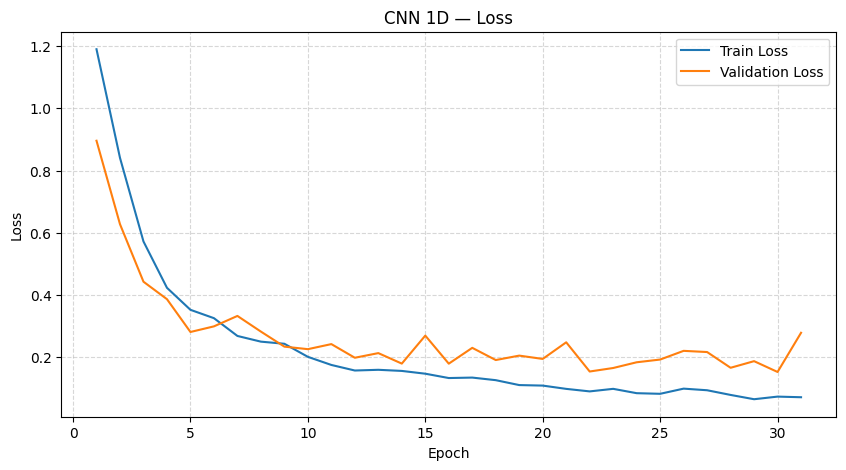

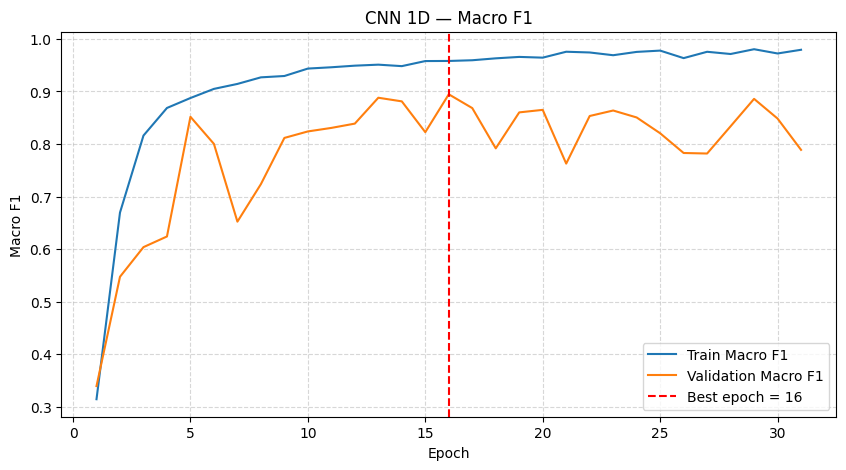

In [ ]:
history_df = pd.DataFrame(history)

# Plot 1: Loss (Train vs Val)
plt.figure(figsize=(10, 5))
plt.plot(history_df['epoch'], history_df['train_loss'], label='Train Loss')
plt.plot(history_df['epoch'], history_df['val_loss'], label='Validation Loss')
plt.title('CNN 1D — Loss')
plt.xlabel('Epoch')
plt.ylabel('Loss')
plt.legend()
plt.grid(True, linestyle='--', alpha=0.5)
plt.show()

# Plot 2: Macro F1 (Train vs Val)
plt.figure(figsize=(10, 5))
plt.plot(history_df['epoch'], history_df['train_macro_f1'], label='Train Macro F1')
plt.plot(history_df['epoch'], history_df['val_macro_f1'], label='Validation Macro F1')
plt.axvline(best_epoch, color='red', linestyle='--', label=f'Best epoch = {best_epoch}')
plt.title('CNN 1D — Macro F1')
plt.xlabel('Epoch')
plt.ylabel('Macro F1')
plt.legend()
plt.grid(True, linestyle='--', alpha=0.5)
plt.show()


## 9. Evaluasi Final pada Test Set

In [ ]:
from sklearn.metrics import matthews_corrcoef, roc_auc_score

def evaluate_cnn1d(model, loader, split_name='Test'):
    loss, macro_f1, y_true_eval, y_pred_eval, y_prob_eval = run_evaluation(model, loader, criterion)

    metrics = {
        'Split': split_name,
        'Accuracy': accuracy_score(y_true_eval, y_pred_eval),
        'Macro Precision': precision_score(y_true_eval, y_pred_eval, average='macro', zero_division=0),
        'Macro Recall': recall_score(y_true_eval, y_pred_eval, average='macro', zero_division=0),
        'Macro F1': f1_score(y_true_eval, y_pred_eval, average='macro', zero_division=0),
        'Balanced Accuracy': balanced_accuracy_score(y_true_eval, y_pred_eval),
        'MCC': matthews_corrcoef(y_true_eval, y_pred_eval),
        'ROC AUC (Macro)': roc_auc_score(y_true_eval, y_prob_eval, multi_class='ovr', average='macro'),
    }

    print(f'=== Classification Report — CNN 1D ({split_name} Set) ===')
    print(classification_report(
        y_true_eval,
        y_pred_eval,
        labels=[0, 1, 2, 3],
        target_names=CLASS_NAMES,
        zero_division=0,
    ))

    return metrics, y_true_eval, y_pred_eval, y_prob_eval

# Evaluasi kedua set (Validation & Test)
val_metrics_cnn, y_val_true_cnn, y_val_pred_cnn, y_val_prob_cnn = evaluate_cnn1d(model, val_loader, 'Validation')
test_metrics_cnn, y_test_true_cnn, y_test_pred_cnn, y_test_prob_cnn = evaluate_cnn1d(model, test_loader, 'Test')

# Tampilkan perbandingan metrik evaluasi dalam DataFrame (Lengkap dengan MCC & ROC AUC)
pd.DataFrame([val_metrics_cnn, test_metrics_cnn]).set_index('Split').round(4)


=== Classification Report — CNN 1D (Validation Set) ===
                            precision    recall  f1-score   support

Sehat / Tidak Ada Indikasi       0.97      0.95      0.96       422
Jantung dan Pembuluh Darah       0.89      1.00      0.94         8
      Spes. Penyakit Dalam       0.78      0.86      0.82        84
           Spes. Paru-Paru       0.75      1.00      0.86         3

                  accuracy                           0.94       517
                 macro avg       0.85      0.95      0.89       517
              weighted avg       0.94      0.94      0.94       517

=== Classification Report — CNN 1D (Test Set) ===
                            precision    recall  f1-score   support

Sehat / Tidak Ada Indikasi       0.97      0.96      0.97       422
Jantung dan Pembuluh Darah       0.88      0.88      0.88         8
      Spes. Penyakit Dalam       0.88      0.88      0.88        84
           Spes. Paru-Paru       0.12      0.33      0.18         3

     

,Accuracy,Macro Precision,Macro Recall,Macro F1,Balanced Accuracy,MCC,ROC AUC (Macro)
Split,,,,,,,
Validation,0.9362,0.8487,0.9518,0.8945,0.9518,0.8022,0.9871
Test,0.9420,0.7130,0.7623,0.7258,0.7623,0.8162,0.9731


### Confusion Matrix — CNN 1D

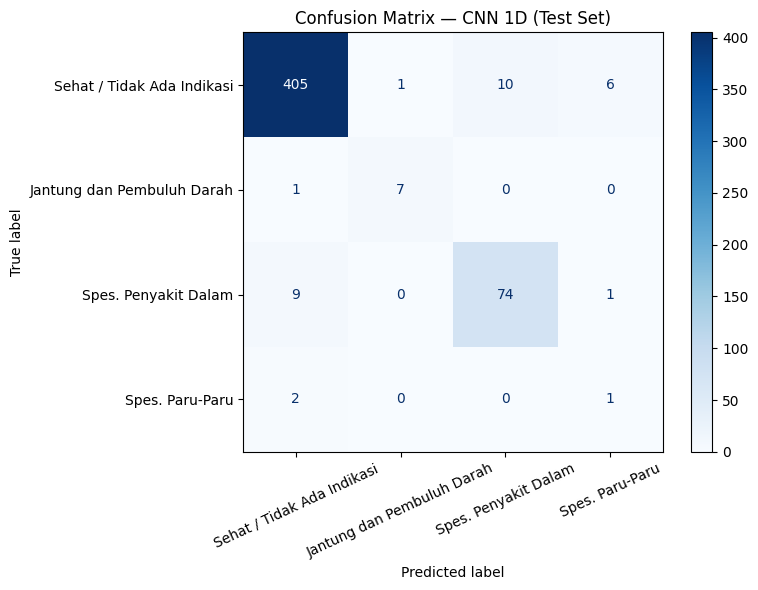

In [ ]:
fig, ax = plt.subplots(figsize=(8, 6))
ConfusionMatrixDisplay.from_predictions(
    y_test,
    y_test_pred_cnn,
    labels=[0, 1, 2, 3],
    display_labels=CLASS_NAMES,
    cmap='Blues',
    xticks_rotation=25,
    ax=ax,
)
plt.title('Confusion Matrix — CNN 1D (Test Set)')
plt.tight_layout()
plt.show()

### Evaluasi Lanjutan: ROC AUC & Matthews Correlation Coefficient (MCC)
Menampilkan skor **MCC** dan visualisasi **Kurva ROC Multiclass (One-vs-Rest)** untuk model CNN 1D.

RINGKASAN METRIK EVALUASI LANJUTAN (TEST SET - CNN 1D)
Matthews Correlation Coefficient (MCC) : 0.8162
Macro-Average ROC AUC (OvR)            : 0.9731


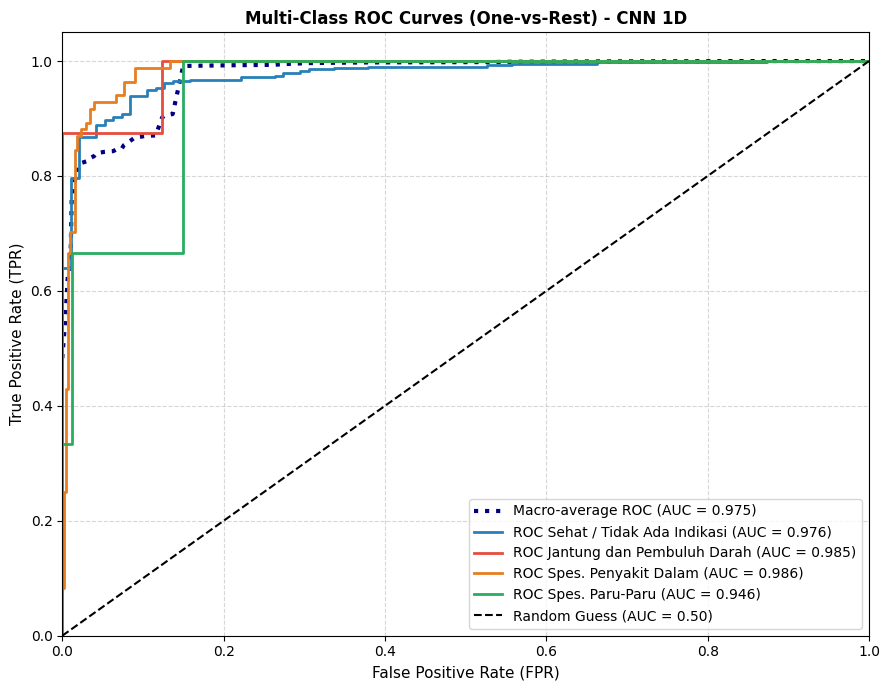

In [ ]:
from sklearn.preprocessing import label_binarize
from sklearn.metrics import roc_curve, auc

# 1. Tampilkan Nilai Metrik Ringkasan
print("=" * 60)
print("RINGKASAN METRIK EVALUASI LANJUTAN (TEST SET - CNN 1D)")
print("=" * 60)
print(f"Matthews Correlation Coefficient (MCC) : {test_metrics_cnn['MCC']:.4f}")
print(f"Macro-Average ROC AUC (OvR)            : {test_metrics_cnn['ROC AUC (Macro)']:.4f}")
print("=" * 60)

# Simpan cnn_metrics untuk tabel perbandingan sel selanjutnya
cnn_metrics = {
    'Model': 'CNN 1D (Test Set)',
    'Accuracy': test_metrics_cnn['Accuracy'],
    'Macro Precision': test_metrics_cnn['Macro Precision'],
    'Macro Recall': test_metrics_cnn['Macro Recall'],
    'Macro F1': test_metrics_cnn['Macro F1'],
    'Balanced Accuracy': test_metrics_cnn['Balanced Accuracy'],
    'MCC': test_metrics_cnn['MCC'],
    'ROC AUC (Macro)': test_metrics_cnn['ROC AUC (Macro)'],
}

# 2. Binarisasi label untuk kurva ROC Multiclass (One-vs-Rest)
y_test_bin = label_binarize(y_test, classes=[0, 1, 2, 3])
n_classes = y_test_bin.shape[1]

fpr = dict()
tpr = dict()
roc_auc = dict()

for i in range(n_classes):
    fpr[i], tpr[i], _ = roc_curve(y_test_bin[:, i], y_test_prob_cnn[:, i])
    roc_auc[i] = auc(fpr[i], tpr[i])

all_fpr = np.unique(np.concatenate([fpr[i] for i in range(n_classes)]))
mean_tpr = np.zeros_like(all_fpr)
for i in range(n_classes):
    mean_tpr += np.interp(all_fpr, fpr[i], tpr[i])
mean_tpr /= n_classes

fpr["macro"] = all_fpr
tpr["macro"] = mean_tpr
roc_auc["macro"] = auc(fpr["macro"], tpr["macro"])

# 3. Plot Kurva ROC
plt.figure(figsize=(9, 7))
plt.plot(fpr["macro"], tpr["macro"], label=f'Macro-average ROC (AUC = {roc_auc["macro"]:.3f})', color='navy', linestyle=':', linewidth=3)
colors = ['#2980b9', '#e74c3c', '#e67e22', '#27ae60']
for i, color in zip(range(n_classes), colors):
    plt.plot(fpr[i], tpr[i], color=color, lw=2, label=f'ROC {CLASS_NAMES[i]} (AUC = {roc_auc[i]:.3f})')

plt.plot([0, 1], [0, 1], 'k--', lw=1.5, label='Random Guess (AUC = 0.50)')
plt.xlim([0.0, 1.0])
plt.ylim([0.0, 1.05])
plt.xlabel('False Positive Rate (FPR)', fontsize=11)
plt.ylabel('True Positive Rate (TPR)', fontsize=11)
plt.title('Multi-Class ROC Curves (One-vs-Rest) - CNN 1D', fontsize=12, fontweight='bold')
plt.legend(loc='lower right', fontsize=10)
plt.grid(True, linestyle='--', alpha=0.5)
plt.tight_layout()
plt.show()


## Catatan Interpretasi

- Bandingkan terutama **Macro-F1** dan **Balanced Accuracy**, selain accuracy, karena keduanya memperlihatkan performa lintas kelas.
- Nilai Conformer pada tabel di atas merupakan angka referensi dari output yang sebelumnya tercatat; nilai CNN dihitung saat notebook ini dijalankan. Pastikan versi dataset, seed, split, dan kode Conformer tetap sama sebelum menyimpulkan perbedaan.
- Karena CNN 1D menerima fitur tabular sebagai urutan, hasilnya dipengaruhi urutan fitur yang ditentukan. Pertahankan urutan `FEATURES` ini ketika menjalankan eksperimen.
- Angka evaluasi tetap menggambarkan dataset hasil balancing Plan B, bukan otomatis kinerja pada distribusi pasien asli.